# PresyoPH – Midterm System Progress Demonstration

A single-file demonstration of data preparation, preprocessing, algorithm implementation,
experimentation, and evaluation for the PresyoPH cost-of-living forecasting system.

**Everything in this notebook comes from the PresyoPH codebase only** (`data_pipeline/`,
`modeling/`, `backend/`, `datasets/`). No external or invented content is added, and no
existing file is modified.

It is organized to match the midterm requirements: Project Overview → Data Preparation
→ Algorithm Implementation → Experimental Results → Q&A preparation.

Run every cell from top to bottom. Working directory must be the PresyoPH project root.
The notebook reads the cleaned CSVs produced by `data_pipeline/preprocess_*.py` and the
model outputs produced by `modeling/run_pipeline.py`, so MySQL is not required to run it.

## Part 1. Project Overview and Objectives

**Project title:** PresyoPH – Philippine cost-of-living dashboard with CPI forecasts.

**Intended users:** Filipino households, students, researchers, and planners who need to
understand how the cost of living is changing in the Philippines.

**Problem addressed:** Households and planners lack a single, accessible view of how prices
are changing nationally, by region, and by commodity group, together with a statistical
forecast of where prices are headed. PresyoPH shows monthly Consumer Price Index (CPI),
inflation rate, and purchasing power of the peso from the Philippine Statistics Authority
(PSA), broken down by region and commodity group, plus CPI forecasts.

**Objectives and expected functionality:** display current prices and inflation; compare
commodity categories; see regional differences; view household finances by income group
(FIES 2023); view CPI forecasts with prediction intervals; generate downloadable reports.
No dashboard is demonstrated at midterm — only the analytical component behind it.

**Dataset and source:** all data is public, aggregate PSA statistics from OpenSTAT
(statistics.bettergov.ph); no personal information is used.
- Consumer Price Index (CPI): monthly, Jan 2018 – Aug 2026, national + 18 regions + 120
  areas + 14 commodity groups (“0 – All Items” and 13 COICOP groups), base year 2018 = 100.
- Inflation rate: monthly, Jan 2019 – Aug 2026, same areas and categories.
- Purchasing power of the peso: monthly, Jan 2018 – Aug 2026, national and areas.
- FIES (Family Income and Expenditure Survey): 2023 only, national and regions, 10 income
  deciles; average income, expenditure, and savings per family.

**Selected algorithms / models (from `modeling/`):** CPI is the sole forecasting target,
per the proposal. Inflation and purchasing power are derived from the CPI forecast using
PSA's own formulas (option B), so modeling CPI alone produces all three forecasts.
Candidate models: ARIMA, Linear Regression, Moving Average (in the proposal), plus ETS
reported as an unofficial extra. Metrics: MAE, RMSE, MAPE.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from modeling import config
from modeling.models import fit_all
from modeling import evaluation as ev
from modeling.derive import to_inflation, to_purchasing_power, derive_all

PROC = ROOT / 'datasets' / 'processed'
OUT  = ROOT / 'datasets' / 'outputs'

plt.rcParams.update({'figure.figsize': (11, 4), 'axes.grid': True, 'grid.alpha': 0.3})
pd.set_option('display.float_format', '{:.3f}'.format)

print('Project root:', ROOT)
print('Target series:', config.TARGET_AREA, '-', config.TARGET_ITEM)
print('Data period:', config.DATA_START.date(), 'to', config.DATA_END.date())
print('Eligible models:', config.PROPOSAL_MODELS)
print('Extra (reported only):', config.EXTRA_MODELS)

Project root: C:\PresyoPH
Target series: PHILIPPINES - 0 - ALL ITEMS
Data period: 2018-01-01 to 2026-08-01
Eligible models: ['ARIMA', 'Linear Regression', 'Moving Average']
Extra (reported only): ['ETS']


## Part 2. Data Preparation and Preprocessing

### Dataset source, observations, and variables

The cleaned CSVs below are the outputs of `data_pipeline/preprocess_cpi.py`,
`preprocess_inflation.py`, `preprocess_purchasing_power.py`, and
`preprocess_fies.py`. Each script reshapes PSA's wide monthly exports to one row per
observation, converts values to numbers, removes months PSA had not yet released
(Sep–Dec 2026, marked “..”), standardizes dates to the first of the month, and
validates row counts, missing values, duplicates, and coverage before writing.

In [2]:
cpi_raw    = pd.read_csv(PROC / 'cpi_clean.csv',    parse_dates=['date'])
inf_raw    = pd.read_csv(PROC / 'inflation_clean.csv', parse_dates=['date'])
pp_raw     = pd.read_csv(PROC / 'purchasing_power_clean.csv', parse_dates=['date'])
fies_raw   = pd.read_csv(PROC / 'fies_clean.csv')

inventory = pd.DataFrame([
    {'dataset': 'CPI',                      'rows': len(cpi_raw),    'areas': cpi_raw['area'].nunique(), 'categories': cpi_raw['category'].nunique(), 'months': cpi_raw['date'].nunique(), 'missing': int(cpi_raw['value'].isna().sum()), 'duplicates': int(cpi_raw.duplicated(subset=['date','area','category']).sum())},
    {'dataset': 'Inflation',                'rows': len(inf_raw),    'areas': inf_raw['area'].nunique(), 'categories': inf_raw['category'].nunique(), 'months': inf_raw['date'].nunique(), 'missing': int(inf_raw['value'].isna().sum()), 'duplicates': int(inf_raw.duplicated(subset=['date','area','category']).sum())},
    {'dataset': 'Purchasing power',         'rows': len(pp_raw),     'areas': pp_raw['area'].nunique(),  'categories': np.nan,                'months': pp_raw['date'].nunique(), 'missing': int(pp_raw['value'].isna().sum()), 'duplicates': int(pp_raw.duplicated(subset=['date','area']).sum())},
    {'dataset': 'FIES 2023',                'rows': len(fies_raw),   'areas': fies_raw['area'].nunique(), 'categories': np.nan,             'months': np.nan,                'missing': int(fies_raw.isna().sum().sum()), 'duplicates': int(fies_raw.duplicated(subset=['year','area','income_group','indicator']).sum())},
])
inventory

,dataset,rows,areas,categories,months,missing,duplicates
0,CPI,174720,120,14.000,104.000,0,0
1,Inflation,154560,120,14.000,92.000,0,0
2,Purchasing power,12480,120,NaN,104.000,0,0
3,FIES 2023,4554,138,NaN,NaN,0,0


In [3]:
print('CPI date range:', cpi_raw['date'].min().date(), 'to', cpi_raw['date'].max().date())
print('Inflation date range:', inf_raw['date'].min().date(), 'to', inf_raw['date'].max().date())
print('Purchasing power date range:', pp_raw['date'].min().date(), 'to', pp_raw['date'].max().date())
print('FIES year:', sorted(fies_raw['year'].unique()))
print()
print('CPI preview:')
print(cpi_raw.head(6).to_string(index=False))

CPI date range: 2018-01-01 to 2026-08-01
Inflation date range: 2019-01-01 to 2026-08-01
Purchasing power date range: 2018-01-01 to 2026-08-01
FIES year: [np.int64(2023)]

CPI preview:
      date     area                                                                category   value  base_year
2018-01-01 ....Abra                                                           0 - ALL ITEMS  98.200       2018
2018-01-01 ....Abra                                   01 - FOOD AND NON-ALCOHOLIC BEVERAGES  95.600       2018
2018-01-01 ....Abra                                    02 - ALCOHOLIC BEVERAGES AND TOBACCO  92.400       2018
2018-01-01 ....Abra                                              03 - CLOTHING AND FOOTWEAR  98.700       2018
2018-01-01 ....Abra                  04 - HOUSING, WATER, ELECTRICITY, GAS, AND OTHER FUELS 104.800       2018
2018-01-01 ....Abra 05 - FURNISHINGS, HOUSEHOLD EQUIPMENT AND ROUTINE HOUSEHOLD MAINTENANCE  99.400       2018


### Target variable and input features

**Target:** national CPI, *0 – All Items* (PHILIPPINES), 2018 = 100. This is the sole
forecasting target per the proposal.

**Input features:** none external. All models are univariate time-series models of CPI:
- ARIMA: past CPI values (differenced), with drift.
- Linear Regression: CPI on a time index t = 1, 2, ... .
- Moving Average: mean of the last k CPI observations.
- ETS (extra): level + trend of past CPI.

Derived variables (not modeled): inflation = (CPI_t / CPI_{t−12} − 1) × 100; purchasing
power = 100 / CPI_t (PSA formulas, `modeling/derive.py`).

In [4]:
# National all-items CPI series used for modeling
cpi = (
    cpi_raw.assign(area=cpi_raw['area'].str.lstrip('.').str.strip())
      .query("area == 'PHILIPPINES' and category == '0 - ALL ITEMS'")
      .set_index('date')['value']
      .sort_index()
      .asfreq('MS')
)
cpi.name = 'cpi'
print('National all-items CPI observations:', len(cpi))
print('Period:', cpi.index.min().date(), 'to', cpi.index.max().date())
print('Missing:', int(cpi.isna().sum()))
display(cpi.describe().to_frame().T)

National all-items CPI observations: 104
Period: 2018-01-01 to 2026-08-01
Missing: 0


,count,mean,std,min,25%,50%,75%,max
cpi,104.000,115.091,11.532,97.200,103.875,113.650,125.775,136.500


### Initial inspection and EDA

Trend, seasonality, and stationarity checks follow `notebooks/01_exploratory_checks.ipynb`.
CPI rose about 40% over the period (strong upward trend). The level is non-stationary;
the first difference is stationary (ADF rejects, KPSS does not), so models use d = 1
with no seasonal differencing. Seasonality is weak (strength of seasonality ≈ 0.17), so
seasonal terms are only a candidate in the ARIMA grid, not a requirement.

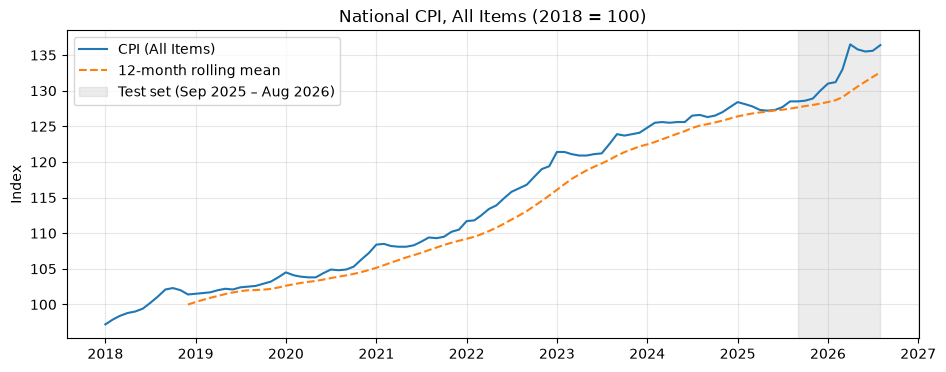

,first,last,mean,change within year (%)
date,,,,
2018,97.200,101.400,99.983,4.321
2019,101.500,103.800,102.375,2.266
2020,104.500,107.200,104.825,2.584
2021,108.400,110.500,108.942,1.937
2022,111.700,119.400,115.283,6.893
2023,121.400,124.100,122.175,2.224
2024,124.800,127.700,126.100,2.324
2025,128.400,130.000,128.192,1.246
2026,131.000,136.400,134.375,4.122


In [5]:
fig, ax = plt.subplots()
ax.plot(cpi, label='CPI (All Items)')
ax.plot(cpi.rolling(12).mean(), label='12-month rolling mean', linestyle='--')
ax.axvspan(config.TEST_START, config.TEST_END, color='grey', alpha=0.15,
           label='Test set (Sep 2025 – Aug 2026)')
ax.set_title('National CPI, All Items (2018 = 100)')
ax.set_ylabel('Index')
ax.legend()
plt.show()

yearly = cpi.groupby(cpi.index.year).agg(['first', 'last', 'mean'])
yearly['change within year (%)'] = (yearly['last'] / yearly['first'] - 1) * 100
display(yearly)

### Data quality issues identified

From the preprocessing scripts and validation outputs:
- **Missing values:** None in the cleaned data. The only raw missing values were the
  unreleased months Sep–Dec 2026 (marked “..”), which are removed, not imputed,
  because they are future months, not gaps.
- **Duplicates:** None after cleaning. CPI_2 and CPI_3 both contain 2023; their
  20,160 overlapping values are identical, so 2023 is taken once (from CPI_3).
- **Inconsistent entries:** PSA's leading dots (encoding geographic level) and
  FIES footnote markers are kept as published; the backend normalizes them for display.
- **Outliers:** No removal. The March–April 2026 price jump (inflation 2.4% → 7.2%)
  is a real shock, not an error, and is retained and discussed in the results.

In [6]:
quality = pd.DataFrame([
    {'check': 'Missing values (CPI)',            'result': int(cpi_raw['value'].isna().sum()),                      'status': 'PASS' if cpi_raw['value'].isna().sum() == 0 else 'FAIL'},
    {'check': 'Missing values (Inflation)',      'result': int(inf_raw['value'].isna().sum()),                     'status': 'PASS' if inf_raw['value'].isna().sum() == 0 else 'FAIL'},
    {'check': 'Missing values (Purchasing power)','result': int(pp_raw['value'].isna().sum()),                    'status': 'PASS' if pp_raw['value'].isna().sum() == 0 else 'FAIL'},
    {'check': 'Missing values (FIES)',           'result': int(fies_raw.isna().sum().sum()),                       'status': 'PASS' if fies_raw.isna().sum().sum() == 0 else 'FAIL'},
    {'check': 'Duplicate observations (CPI)',    'result': int(cpi_raw.duplicated(subset=['date','area','category']).sum()), 'status': 'PASS' if cpi_raw.duplicated(subset=['date','area','category']).sum() == 0 else 'FAIL'},
    {'check': 'Duplicate observations (FIES)',   'result': int(fies_raw.duplicated(subset=['year','area','income_group','indicator']).sum()), 'status': 'PASS' if fies_raw.duplicated(subset=['year','area','income_group','indicator']).sum() == 0 else 'FAIL'},
    {'check': 'CPI months per area/category',    'result': int(cpi_raw.groupby(['area','category'])['date'].nunique().min()), 'status': 'PASS'},
    {'check': 'CPI expected vs actual rows',     'result': f"{len(cpi_raw)} vs {cpi_raw['area'].nunique()*cpi_raw['category'].nunique()*cpi_raw['date'].nunique()}", 'status': 'PASS' if len(cpi_raw) == cpi_raw['area'].nunique()*cpi_raw['category'].nunique()*cpi_raw['date'].nunique() else 'FAIL'},
])
display(quality.to_string(index=False))

'                            check           result status\n             Missing values (CPI)                0   PASS\n       Missing values (Inflation)                0   PASS\nMissing values (Purchasing power)                0   PASS\n            Missing values (FIES)                0   PASS\n     Duplicate observations (CPI)                0   PASS\n    Duplicate observations (FIES)                0   PASS\n     CPI months per area/category              104   PASS\n      CPI expected vs actual rows 174720 vs 174720   PASS'

### Preprocessing steps performed and why

1. **Reshape wide → long** — PSA exports one column per month; analysis needs one
   row per (date, area, category).
2. **Drop annual-average (“Ave”) columns** — they are aggregates, not monthly
   observations.
3. **Convert values to numeric** — “..” markers become NaN and are removed.
4. **Standardize dates** to the first of the month so all three monthly series align.
5. **Add descriptive columns** (base_year = 2018; unit = percent / peso / thousand
   pesos).
6. **Combine overlapping years** and de-duplicate without conflict.
7. **Sort and validate** before writing; nothing is written if a check fails.

**Feature selection / encoding / scaling:** Not performed, and intentionally so. The
models are univariate time-series models of CPI with no categorical predictors, so there
is nothing to encode, and no feature matrix to scale. FIES is descriptive only (a 2023
snapshot) and is not forecast.

## Part 3. Algorithm Implementation, Model Development, and Experimentation

### How the selected method works and why it is appropriate

CPI has a strong trend and is non-stationary in levels, so the appropriate approach is
to model the differenced series.

- **ARIMA(p, 1, q) with drift:** differences once (d = 1, from stationarity checks),
  adds a constant average monthly change (drift), and chooses p, q ∈ {0, 1, 2} plus an
  optional seasonal AR(1)<sub>12</sub> by AIC with a parsimony rule (candidates within 2 AIC
  points of the best are tied; the fewest-parameter one wins). Appropriate because CPI
  is trending and autocorrelated at lag 1.

- **Linear Regression:** CPI = a + b × t fitted by OLS on a time index. Captures the
  long-run trend but cannot adapt to sudden shifts.

- **Moving Average:** flat forecast equal to the mean of the last k months; k ∈ {3,
  6, 12} chosen by lowest RMSE on a validation window (the last 12 training months).
  Simple baseline that assumes the recent level persists.

- **ETS (extra, not in the proposal):** Holt's method with additive error and trend,
  damped or not, chosen by AIC. Reported for comparison only; not eligible for selection.

### Train / test split

For time series the test size is set by the forecast horizon (12 months, matching the
dashboard's maximum horizon), not a fixed percentage. Training keeps 7.7 years of data.

Train: Jan 2018 – Aug 2025  (92 months)
Test:  Sep 2025  – Aug 2026  (12 months)
Split: 88.5% / 11.5%


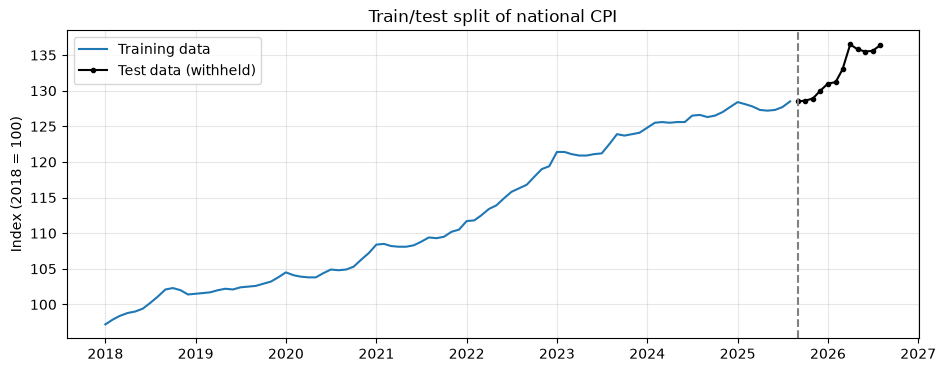

In [7]:
train = cpi[: config.TRAIN_END]
test  = cpi[config.TEST_START : config.TEST_END]

print(f'Train: {train.index[0]:%b %Y} – {train.index[-1]:%b %Y}  ({len(train)} months)')
print(f'Test:  {test.index[0]:%b %Y}  – {test.index[-1]:%b %Y}  ({len(test)} months)')
print(f'Split: {len(train)/len(cpi):.1%} / {len(test)/len(cpi):.1%}')

fig, ax = plt.subplots()
ax.plot(train, label='Training data')
ax.plot(test, color='black', marker='o', markersize=3, label='Test data (withheld)')
ax.axvline(config.TEST_START, color='grey', linestyle='--')
ax.set_title('Train/test split of national CPI')
ax.set_ylabel('Index (2018 = 100)')
ax.legend()
plt.show()

### Model implementation and tuning (training data only)

All four models are fitted on the training data only, exactly as in
`modeling/models.py`, with settings from `modeling/config.py`.

In [8]:
results = fit_all(train, horizon=config.HORIZON)
params = {name: r.params for name, r in results.items()}
display(pd.DataFrame(params).T)

,order,seasonal_order,aic,drift_per_month,intercept,slope_per_month,r_squared,k,level,damped_trend,smoothing_level,smoothing_trend
ARIMA,"(1, 1, 0)","(0, 0, 0, 0)",116.714,0.349,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Linear Regression,NaN,NaN,NaN,NaN,95.367,0.375,0.968,NaN,NaN,NaN,NaN,NaN
Moving Average,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.000,127.833,NaN,NaN,NaN
ETS,NaN,NaN,134.356,NaN,NaN,NaN,NaN,NaN,NaN,False,1.000,0.088


#### ARIMA candidate selection (AIC + parsimony rule)

In [9]:
arima = results['ARIMA']
cand = arima.candidates.copy()
cand['order'] = cand['order'].astype(str)
cand['seasonal_order'] = cand['seasonal_order'].astype(str)
display(cand[['order','seasonal_order','aic','n_params','converged','selected']].sort_values('aic').reset_index(drop=True))
print('\nChosen ARIMA order:', arima.params['order'], '| seasonal:', arima.params['seasonal_order'],
      '| drift/month:', round(arima.params['drift_per_month'], 4))

,order,seasonal_order,aic,n_params,converged,selected
0,"(0, 1, 1)","(1, 0, 0, 12)",115.677,4,True,False
1,"(1, 1, 0)","(0, 0, 0, 0)",116.714,3,True,True
2,"(1, 1, 0)","(1, 0, 0, 12)",116.719,4,True,False
3,"(0, 1, 1)","(0, 0, 0, 0)",116.774,3,True,False
4,"(1, 1, 1)","(1, 0, 0, 12)",117.665,5,True,False
5,"(0, 1, 2)","(1, 0, 0, 12)",117.675,5,True,False
6,"(2, 1, 0)","(1, 0, 0, 12)",117.727,5,True,False
7,"(2, 1, 2)","(0, 0, 0, 0)",117.775,6,True,False
8,"(2, 1, 0)","(0, 0, 0, 0)",118.194,4,True,False
9,"(1, 1, 1)","(0, 0, 0, 0)",118.339,4,True,False



Chosen ARIMA order: (1, 1, 0) | seasonal: (0, 0, 0, 0) | drift/month: 0.3487


#### Linear Regression fit diagnostics

CPI = 95.367 + 0.3751 × t   (R² = 0.968)
Durbin–Watson statistic: 0.068 (near 2 = independent residuals)


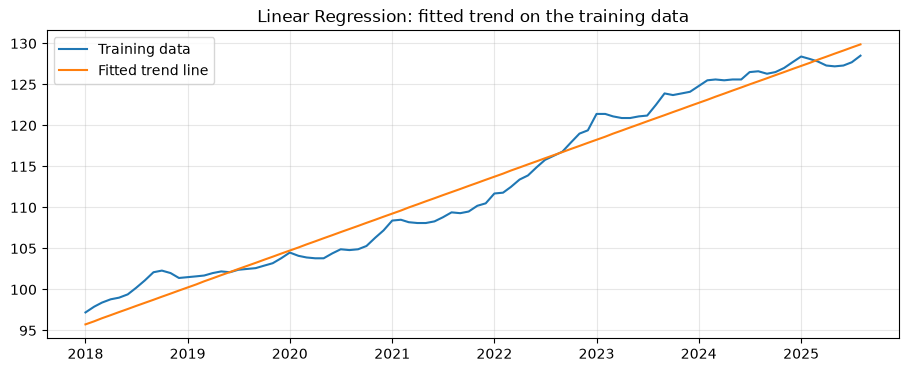

In [10]:
from statsmodels.stats.stattools import durbin_watson

lr = results['Linear Regression']
print(f"CPI = {lr.params['intercept']:.3f} + {lr.params['slope_per_month']:.4f} × t   (R² = {lr.params['r_squared']:.3f})")
print(f"Durbin\u2013Watson statistic: {durbin_watson(lr.fitted.resid):.3f} (near 2 = independent residuals)")

t = np.arange(1, len(train) + 1)
fig, ax = plt.subplots()
ax.plot(train, label='Training data')
ax.plot(train.index, lr.fitted.fittedvalues, color='tab:orange', label='Fitted trend line')
ax.set_title('Linear Regression: fitted trend on the training data')
ax.legend()
plt.show()

#### Moving Average window selection (validation window)

In [11]:
ma = results['Moving Average']
print(f"Chosen window: k = {ma.params['k']}  →  forecast level {ma.params['level']:.2f}")
display(ma.candidates)

Chosen window: k = 3  →  forecast level 127.83


,k,validation_rmse
0,3,1.413
1,6,1.715
2,12,2.464


#### ETS (extra, reported only)

In [12]:
ets = results['ETS']
print({k: v for k, v in ets.params.items()})
display(ets.candidates)

{'damped_trend': False, 'aic': np.float64(134.35560424692454), 'smoothing_level': 0.9999, 'smoothing_trend': 0.08803063764362899}


,damped_trend,aic,n_params,converged,delta_aic,selected
0,False,134.356,4,True,0.000,True
1,True,135.899,5,True,1.544,False


#### Residual diagnostics (ARIMA at the test origin)

A good ARIMA leaves residuals that look like random noise: no autocorrelation,
centred on zero.

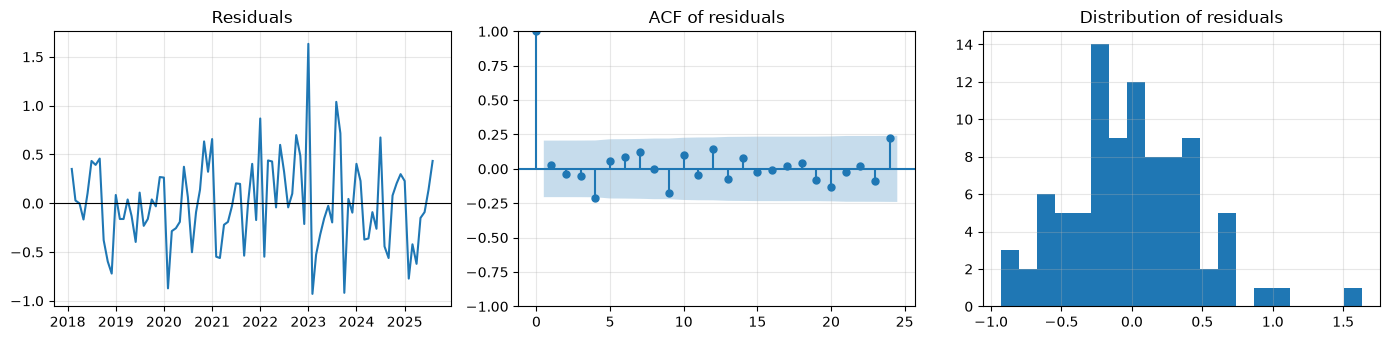

    lb_stat  lb_pvalue
6     5.874      0.437
12   14.135      0.292
24   25.801      0.363


In [13]:
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.graphics.tsaplots import plot_acf

resid = arima.fitted.resid.iloc[1:]

fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
axes[0].plot(resid); axes[0].axhline(0, color='black', linewidth=0.8); axes[0].set_title('Residuals')
plot_acf(resid, lags=24, ax=axes[1], title='ACF of residuals')
axes[2].hist(resid, bins=20); axes[2].set_title('Distribution of residuals')
fig.tight_layout()
plt.show()

print(acorr_ljungbox(resid, lags=[6, 12, 24], return_df=True))

### Experiments conducted

- Main test: train Jan 2018 – Aug 2025, forecast Sep 2025 – Aug 2026 (12 months).
- Rolling-origin evaluation: five earlier origins (Aug 2022, Feb 2023, Aug 2023,
  Feb 2024, Aug 2024), each forecasting 12 months with an expanding window and re-tuned
  using only data up to that origin.
- Alternative models/parameters: ARIMA grid (18 candidates), Moving Average windows
  {3, 6, 12}, ETS damped vs. undamped.
- Baseline/comparison: Linear Regression and Moving Average serve as simple baselines;
  ARIMA is the proposed primary model.

### Test-period forecasts by model

Shaded bands are 95% prediction intervals.

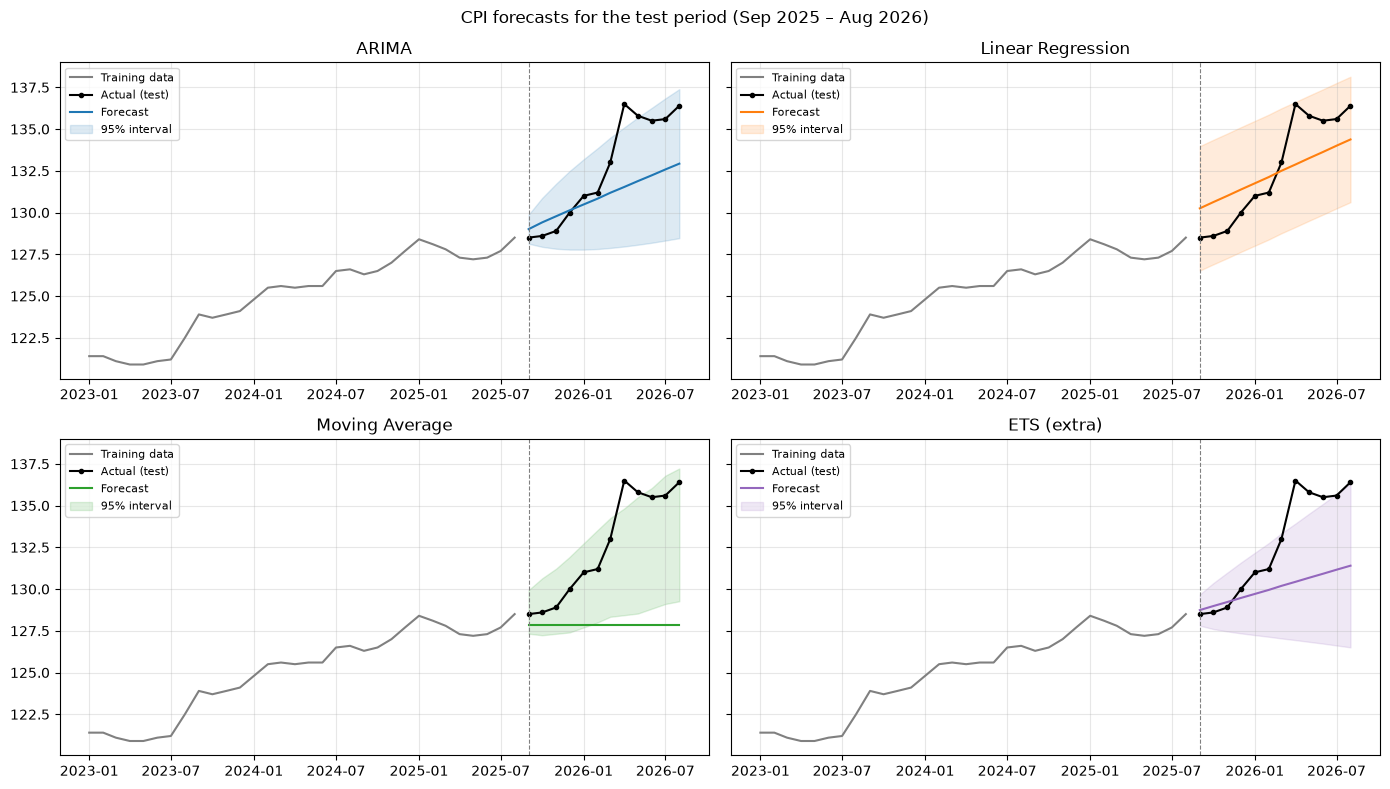

,actual,ARIMA,Linear Regression,Moving Average,ETS
2025-09-01,128.500,129.010,130.250,127.830,128.740
2025-10-01,128.600,129.410,130.630,127.830,128.980
2025-11-01,128.900,129.780,131.000,127.830,129.230
2025-12-01,130.000,130.140,131.380,127.830,129.470
2026-01-01,131.000,130.490,131.750,127.830,129.710
2026-02-01,131.200,130.840,132.130,127.830,129.950
2026-03-01,133.000,131.190,132.500,127.830,130.190
2026-04-01,136.500,131.530,132.880,127.830,130.430
2026-05-01,135.800,131.880,133.250,127.830,130.680
2026-06-01,135.500,132.230,133.630,127.830,130.920


In [14]:
COLORS = {'ARIMA': 'tab:blue', 'Linear Regression': 'tab:orange', 'Moving Average': 'tab:green', 'ETS': 'tab:purple'}
history = cpi['2023-01':config.TRAIN_END]

fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharey=True)
for ax, (name, r) in zip(axes.flat, results.items()):
    ax.plot(history, color='grey', label='Training data')
    ax.plot(test, color='black', marker='o', markersize=3, label='Actual (test)')
    ax.plot(r.forecast, color=COLORS[name], label='Forecast')
    ax.fill_between(r.forecast.index, r.lower, r.upper, color=COLORS[name], alpha=0.15,
                    label='95% interval')
    ax.axvline(config.TEST_START, color='grey', linestyle='--', linewidth=0.8)
    ax.set_title(name + (' (extra)' if name in config.EXTRA_MODELS else ''))
    ax.legend(fontsize=8, loc='upper left')
fig.suptitle('CPI forecasts for the test period (Sep 2025 – Aug 2026)')
fig.tight_layout()
plt.show()

forecast_table = pd.DataFrame({'actual': test, **{name: r.forecast for name, r in results.items()}})
display(forecast_table.round(2))

## Part 4. Experimental Results and Evaluation

### Evaluation metrics

MAE, RMSE, and MAPE (forecasting). MAE and RMSE for CPI are in index points; MAPE in
percent. Inflation MAPE is large and unstable when actual inflation is low, so it is
read alongside MAE and RMSE.

### Main test metrics (Sep 2025 – Aug 2026) and sub-periods

In [15]:
inf_series = (
    inf_raw.assign(area=inf_raw['area'].str.lstrip('.').str.strip())
      .query("area == 'PHILIPPINES' and category == '0 - ALL ITEMS'")
      .set_index('date')['value']
      .sort_index()
      .asfreq('MS')
)
pp_series = (
    pp_raw.assign(area=pp_raw['area'].str.lstrip('.').str.strip())
      .query("area == 'PHILIPPINES'")
      .set_index('date')['value']
      .sort_index()
      .asfreq('MS')
)
actuals = {'cpi': cpi, 'inflation': inf_series, 'purchasing_power': pp_series}
_, main = ev.forecast_from(cpi, config.TRAIN_END)
main = ev.attach_actuals(main, actuals)

for label, (start, end) in config.TEST_SUBPERIODS.items():
    m = ev.metrics_table(main, start, end)
    print('\n###', label)
    pivot = m.pivot(index='model', columns='variable', values=config.METRICS)
    pivot = pivot.swaplevel(axis=1)[[v for v in config.VARIABLES]]
    pivot = pivot.reindex(columns=config.METRICS, level=1).rename(columns={'cpi':'CPI','inflation':'Inflation','purchasing_power':'Purchasing power'}, level=0)
    display(pivot.reindex(config.PROPOSAL_MODELS + config.EXTRA_MODELS).round(3))


### full test (Sep 2025 - Aug 2026)


variable            CPI             Inflation              Purchasing power  \
                    MAE  RMSE  MAPE       MAE  RMSE   MAPE              MAE   
model                                                                         
ARIMA             1.972 2.537 1.463     1.550 1.992 33.493            0.012   
Linear Regression 1.758 1.935 1.321     1.375 1.510 46.298            0.009   
Moving Average    4.750 5.671 3.530     3.708 4.436 85.687            0.025   
ETS               2.671 3.422 1.978     2.092 2.673 43.127            0.016   

variable                       
                   RMSE  MAPE  
model                          
ARIMA             0.015 1.568  
Linear Regression 0.011 1.216  
Moving Average    0.031 3.373  
ETS               0.020 2.136


### before shock (Sep 2025 - Feb 2026)


variable            CPI             Inflation              Purchasing power  \
                    MAE  RMSE  MAPE       MAE  RMSE   MAPE              MAE   
model                                                                         
ARIMA             0.535 0.592 0.414     0.417 0.460 23.924            0.005   
Linear Regression 1.490 1.578 1.152     1.183 1.256 68.347            0.008   
Moving Average    1.867 2.169 1.432     1.433 1.666 73.469            0.008   
ETS               0.671 0.798 0.514     0.533 0.630 27.217            0.005   

variable                       
                   RMSE  MAPE  
model                          
ARIMA             0.007 0.647  
Linear Regression 0.011 1.071  
Moving Average    0.012 1.094  
ETS               0.007 0.652


### after shock (Mar 2026 - Aug 2026)


variable            CPI             Inflation              Purchasing power  \
                    MAE  RMSE  MAPE       MAE  RMSE   MAPE              MAE   
model                                                                         
ARIMA             3.409 3.539 2.512     2.683 2.780 43.062            0.018   
Linear Regression 2.026 2.235 1.490     1.567 1.727 24.248            0.010   
Moving Average    7.633 7.722 5.628     5.983 6.049 97.904            0.042   
ETS               4.670 4.773 3.442     3.650 3.728 59.038            0.027   

variable                       
                   RMSE  MAPE  
model                          
ARIMA             0.020 2.490  
Linear Regression 0.012 1.361  
Moving Average    0.042 5.652  
ETS               0.028 3.619

### Rolling-origin evaluation (five earlier origins)

In [16]:
rolling, fold_metrics = ev.rolling_origin(cpi, actuals)
print('Average over the five rolling-origin folds (pooled CPI focus):')
avg = ev.average_over_folds(fold_metrics)
display(avg[avg['variable']=='cpi'].round(3))

Average over the five rolling-origin folds (pooled CPI focus):


,model,variable,MAE,RMSE,MAPE
0,ARIMA,cpi,1.658,1.834,1.334
3,Linear Regression,cpi,2.858,2.961,2.321
6,Moving Average,cpi,2.655,2.928,2.141
9,ETS,cpi,1.980,2.181,1.596


### Pooled evaluation: all six origins (72 forecast months per model) — selection basis

In [17]:
pooled = pd.concat([rolling, main], ignore_index=True)
pooled_metrics = ev.metrics_table(pooled)
pivot = pooled_metrics.pivot(index='model', columns='variable', values=config.METRICS)
pivot = pivot.swaplevel(axis=1)[[v for v in config.VARIABLES]]
pivot = pivot.reindex(columns=config.METRICS, level=1).rename(columns={'cpi':'CPI','inflation':'Inflation','purchasing_power':'Purchasing power'}, level=0)
display(pivot.reindex(config.PROPOSAL_MODELS + config.EXTRA_MODELS).round(3))

variable            CPI             Inflation              Purchasing power  \
                    MAE  RMSE  MAPE       MAE  RMSE   MAPE              MAE   
model                                                                         
ARIMA             1.710 2.009 1.356     1.419 1.661 42.717            0.012   
Linear Regression 2.674 3.144 2.155     2.254 2.693 56.026            0.017   
Moving Average    3.004 3.710 2.373     2.479 3.053 63.313            0.016   
ETS               2.095 2.612 1.660     1.740 2.163 50.106            0.014   

variable                       
                   RMSE  MAPE  
model                          
ARIMA             0.014 1.449  
Linear Regression 0.021 2.044  
Moving Average    0.021 2.041  
ETS               0.018 1.764

### Model selection (2-of-3-metrics rule on CPI; else lowest RMSE)

In [18]:
rows = []
for basis_label, metrics in [('Pooled, six origins (selection basis)', pooled_metrics),
                             ('Main test only (original plan)', ev.metrics_table(main, config.TEST_START, config.TEST_END))]:
    for label, models in [('proposal models', config.PROPOSAL_MODELS),
                          ('including ETS', config.PROPOSAL_MODELS + config.EXTRA_MODELS)]:
        winner, explanation, wins = ev.select_model(metrics, models=models)
        rows.append({'evaluation': basis_label, 'models': label, 'winner': winner, 'reason': explanation})
pd.set_option('display.max_colwidth', None)
display(pd.DataFrame(rows))

,evaluation,models,winner,reason
0,"Pooled, six origins (selection basis)",proposal models,ARIMA,"ARIMA has the lowest MAE, RMSE, MAPE (3 of 3 metrics)."
1,"Pooled, six origins (selection basis)",including ETS,ARIMA,"ARIMA has the lowest MAE, RMSE, MAPE (3 of 3 metrics)."
2,Main test only (original plan),proposal models,Linear Regression,"Linear Regression has the lowest MAE, RMSE, MAPE (3 of 3 metrics)."
3,Main test only (original plan),including ETS,Linear Regression,"Linear Regression has the lowest MAE, RMSE, MAPE (3 of 3 metrics)."


In [19]:
final_model, explanation, wins, _ = ev.select_final_model(main, rolling)
print(f'Selection basis: {config.SELECTION_BASIS}')
print(f'Final model: {final_model}')
print(explanation)
print('Metric wins:', {k: int(v) for k, v in wins.items()})

Selection basis: pooled
Final model: ARIMA
ARIMA has the lowest MAE, RMSE, MAPE (3 of 3 metrics).
Metric wins: {'ARIMA': 3, 'Linear Regression': 0, 'Moving Average': 0}


### Error by forecast step (pooled over six origins)

model,ARIMA,Linear Regression,Moving Average,ETS
step,,,,
1,0.494,2.545,0.889,0.571
2,0.875,2.438,1.039,0.907
3,1.183,2.481,1.406,1.170
4,1.185,2.324,1.839,1.321
5,1.541,2.667,2.739,1.788
6,1.437,2.710,3.072,1.894
7,1.705,2.615,3.472,2.171
8,2.497,3.010,3.922,2.942
9,2.432,2.821,3.922,2.986


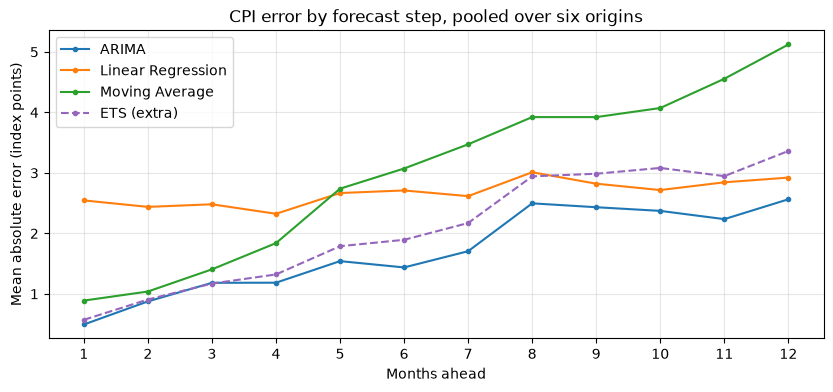

In [20]:
MODEL_ORDER = config.PROPOSAL_MODELS + config.EXTRA_MODELS
by_step = ev.error_by_step(pooled)[MODEL_ORDER]
display(by_step.round(3))

fig, ax = plt.subplots(figsize=(10, 4))
for model in MODEL_ORDER:
    ax.plot(by_step.index, by_step[model], marker='o', markersize=3,
            color=COLORS[model],
            linestyle='--' if model in config.EXTRA_MODELS else '-',
            label=model + (' (extra)' if model in config.EXTRA_MODELS else ''))
ax.set_xlabel('Months ahead')
ax.set_ylabel('Mean absolute error (index points)')
ax.set_title('CPI error by forecast step, pooled over six origins')
ax.set_xticks(range(1, config.HORIZON + 1))
ax.legend()
plt.show()

### Final forecast (refit on all data, Sep 2026 – Aug 2027)

In [21]:
final_results, final_predictions = ev.forecast_from(cpi, config.DATA_END, models=[final_model])
final = final_results[final_model]
print(f'{final_model} settings on all data: {final.params}')

final_table = derive_all(cpi, final.forecast)
final_table['cpi_lower'], final_table['cpi_upper'] = final.lower, final.upper
display(final_table.round(2))

import json
info = json.loads((OUT / 'model_info.json').read_text(encoding='utf-8'))
print('\nSaved outputs:', [p.name for p in sorted(OUT.glob('*'))])
print('Final model recorded in model_info.json:', info['final_model'])

ARIMA settings on all data: {'order': (0, 1, 1), 'seasonal_order': (0, 0, 0, 0), 'aic': np.float64(179.1990449090025), 'drift_per_month': 0.3830893366197122}


,cpi,inflation,purchasing_power,cpi_lower,cpi_upper
2026-09-01,136.950,6.600,0.730,135.850,138.050
2026-10-01,137.330,6.800,0.730,135.510,139.160
2026-11-01,137.710,6.800,0.730,135.380,140.050
2026-12-01,138.100,6.200,0.720,135.340,140.850
2027-01-01,138.480,5.700,0.720,135.360,141.600
2027-02-01,138.860,5.800,0.720,135.420,142.310
2027-03-01,139.250,4.700,0.720,135.510,142.990
2027-04-01,139.630,2.300,0.720,135.620,143.640
2027-05-01,140.010,3.100,0.710,135.740,144.280
2027-06-01,140.400,3.600,0.710,135.880,144.910



Saved outputs: ['error_by_step.csv', 'forecasts.csv', 'metrics.csv', 'model_info.json', 'README.md', 'test_predictions.csv']
Final model recorded in model_info.json: ARIMA


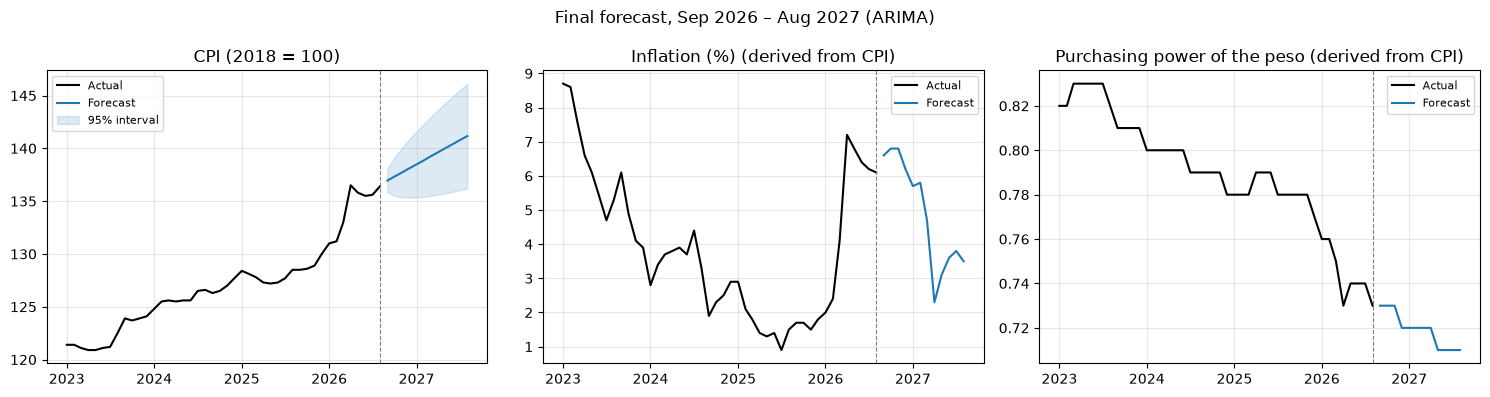

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
history_start = '2023-01'
inf_hist = actuals['inflation']
pp_hist = actuals['purchasing_power']

axes[0].plot(cpi[history_start:], color='black', label='Actual')
axes[0].plot(final.forecast, color=COLORS[final_model], label='Forecast')
axes[0].fill_between(final.forecast.index, final.lower, final.upper, color=COLORS[final_model], alpha=0.15,
                     label='95% interval')
axes[0].set_title('CPI (2018 = 100)')
axes[0].legend(fontsize=8)

axes[1].plot(inf_hist[history_start:], color='black', label='Actual')
axes[1].plot(final_table['inflation'], color=COLORS[final_model], label='Forecast')
axes[1].set_title('Inflation (%) (derived from CPI)')
axes[1].legend(fontsize=8)

axes[2].plot(pp_hist[history_start:], color='black', label='Actual')
axes[2].plot(final_table['purchasing_power'], color=COLORS[final_model], label='Forecast')
axes[2].set_title('Purchasing power of the peso (derived from CPI)')
axes[2].legend(fontsize=8)

for ax in axes:
    ax.axvline(config.DATA_END, color='grey', linestyle='--', linewidth=0.8)
fig.suptitle(f'Final forecast, Sep 2026 – Aug 2027 ({final_model})')
fig.tight_layout()
plt.show()

### Interpretation of the results

- **Pooled evaluation (selection basis):** ARIMA has the lowest CPI error on all three
  metrics (MAE 1.71, RMSE 2.01, MAPE 1.36% over 72 forecast months) and is also best for
  derived inflation and purchasing power, so one model serves all three forecasts.
- **Main test alone:** Linear Regression wins (RMSE 1.93 vs. ARIMA 2.54), but largely
  because the March–April 2026 price shock lifted actual CPI up to its trend line. Before
  the shock ARIMA was clearly most accurate (RMSE 0.59 vs. 1.58).
- **Rolling origin:** ARIMA ranks first at the three earlier origins; Linear Regression
  at the three most recent. The ranking is not stable across periods.
- **Error grows with horizon:** ARIMA's MAE rises from ≈0.49 (1 month) to ≈2.56
  (12 months), so the dashboard's 3-month view is more reliable than its 12-month view.
- **Limitations:** models use past CPI only and cannot anticipate external shocks (fuel,
  policy, disasters); the March–April 2026 jump is outside every model's 95% interval in
  April–May 2026; inflation MAPE is unstable when inflation is low; the selection basis
  was changed to the pooled results after seeing them, which is disclosed.

## Part 5. Questions and Answers (preparation)

Key facts each member should be able to explain, all drawn from this notebook and the
codebase:

1. **How the dataset was obtained, examined, and prepared:** PSA OpenSTAT exports
   (CPI_1–3.xlsx, Inflation_1–2.xlsx, PurchasingPower.xlsx, FIES.csv) were cleaned by
   `data_pipeline/preprocess_*.py`: wide-to-long reshape, numeric conversion, removal of
   unreleased months (Sep–Dec 2026), date standardization, de-duplication, and validation
   (no missing values, no duplicates, full monthly coverage). Cleaned CSVs in
   `datasets/processed/`; loaded into MySQL `presyoph_db` by `load_database.py`.

2. **Preprocessing decisions and justification:** wide-to-long for analysis alignment;
   unreleased months removed rather than imputed (they are future months); no encoding/
   scaling because models are univariate time series of CPI; FIES kept as a 2023 snapshot,
   not forecast.

3. **Algorithm executed:** CPI forecast with ARIMA, Linear Regression, and Moving Average
   (+ ETS reported only), trained on Jan 2018 – Aug 2025, evaluated on Sep 2025 – Aug
   2026 plus five rolling origins; ARIMA selected on the pooled 72-month evaluation.

4. **Actual experimental results:** pooled CPI MAE 1.71 / RMSE 2.01 / MAPE 1.36% (ARIMA);
   main-test CPI RMSE 2.54 (ARIMA) vs. 1.93 (Linear Regression); error grows from ≈0.49
  
1 month to ≈2.56 at 12 months.

5. **Interpretation, limitations, improvements:** past-CPI-only models cannot anticipate
  external shocks; results reported before/after the March–April 2026 shock; selection
  basis change disclosed; possible improvements include adding ETS if approved and more
  evaluation data as it arrives.

6. **How the analytical component supports the system:** the selected CPI forecast drives
   the dashboard's CPI, inflation, and purchasing power forecasts with 95% intervals, so
   users see a consistent, statistically grounded outlook for the cost of living.

---
*End of single-file midterm demonstration. All code, data, and results are from the
PresyoPH codebase (`data_pipeline/`, `modeling/`, `backend/`, `datasets/`). No existing
file was modified; this notebook is additive only.*